# Flow matching · CIFAR-10

$$
x=\frac{\mathrm{pixel}}{127.5}-1\in[-1,1]^{32\times32\times3}.
$$


In [2]:
from functools import partial
import numpy as np
from scipy.ndimage import gaussian_filter, map_coordinates
from sklearn.decomposition import PCA
from datasets import load_dataset
import jax
import jax.numpy as jnp
from model import init_model, model_apply

rng = np.random.default_rng(0)
data = load_dataset("uoft-cs/cifar10")
X_train = np.stack([np.asarray(img) for img in data["train"]["img"]])
X_train = X_train.astype(np.float32) / 127.5 - 1
y_train = np.asarray(data["train"]["label"])
class_names = data["train"].features["label"].names


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def rgb(x):
    return np.clip((np.asarray(x) + 1) / 2, 0, 1)


def image_grid(images):
    return (rgb(images).reshape(4, 4, 32, 32, 3)
            .transpose(0, 2, 1, 3, 4).reshape(128, 128, 3))


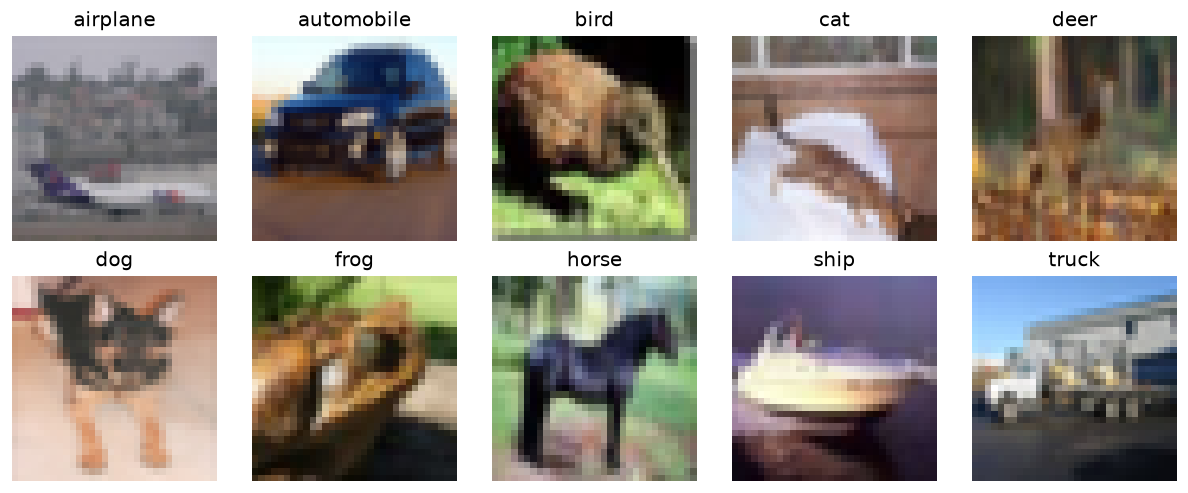

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4), layout="constrained")
for label, ax in enumerate(axes.flat):
    i = np.flatnonzero(y_train == label)[0]
    ax.imshow(rgb(X_train[i]), interpolation="nearest")
    ax.set_title(class_names[label])
    ax.set_axis_off()
plt.show()

## Linear path

$$
X_0\sim\mathcal N(0,I),\quad X_1\sim p_{\mathrm{data}},\quad
X_0\perp X_1,\quad T\sim U[0,1].
$$
$$
X_t=(1-t)X_0+tX_1,\qquad V=\dot X_t=X_1-X_0.
$$


In [5]:
def make_flow_batch(x1, key):
    noise_key, time_key = jax.random.split(key)
    x0 = jax.random.normal(noise_key, x1.shape)
    t = jax.random.uniform(time_key, (len(x1), 1, 1, 1))
    xt = (1 - t) * x0 + t * x1
    return x0, xt, t, x1 - x0


indices = rng.choice(len(X_train), 3000, replace=False)
x1 = jnp.asarray(X_train[indices])
x0, xt, t, target = make_flow_batch(x1, jax.random.key(0))
times = np.linspace(0, 1, 5)
pair_paths = np.stack([(1 - ti) * np.asarray(x0[:4]) + ti * np.asarray(x1[:4])
                       for ti in times])
velocity = np.asarray(target[0])


### Fixed pairs

RGB display: $\operatorname{clip}((x+1)/2,0,1)$.


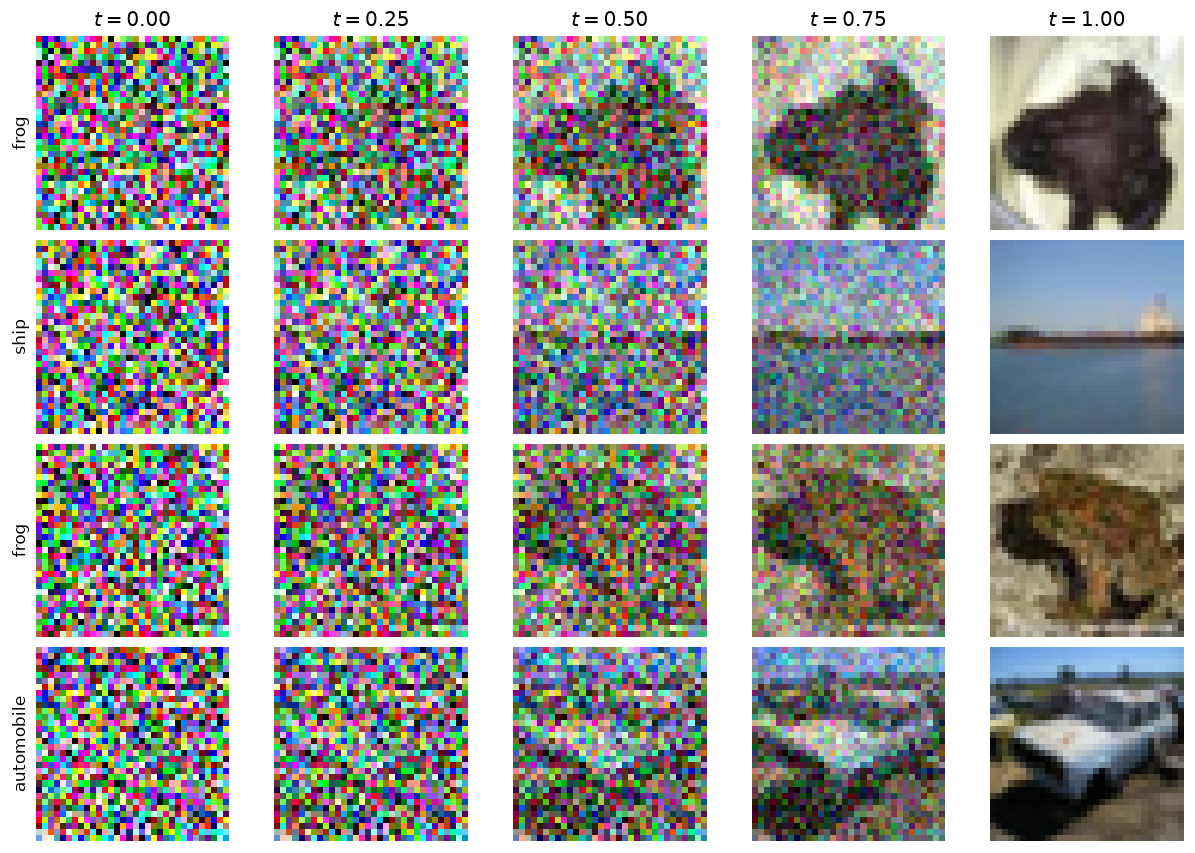

In [6]:
fig, axes = plt.subplots(4, 5, figsize=(10, 7), layout="constrained")
for row in range(4):
    for col, ti in enumerate(times):
        ax = axes[row, col]
        ax.imshow(rgb(pair_paths[col, row]),
                  interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.set_title(f"$t={ti:.2f}$")
        if col == 0:
            ax.set_ylabel(class_names[y_train[indices[row]]])
plt.show()


### Target velocity

$$
V_c=X_{1,c}-X_{0,c},\qquad c\in\{R,G,B\}.
$$


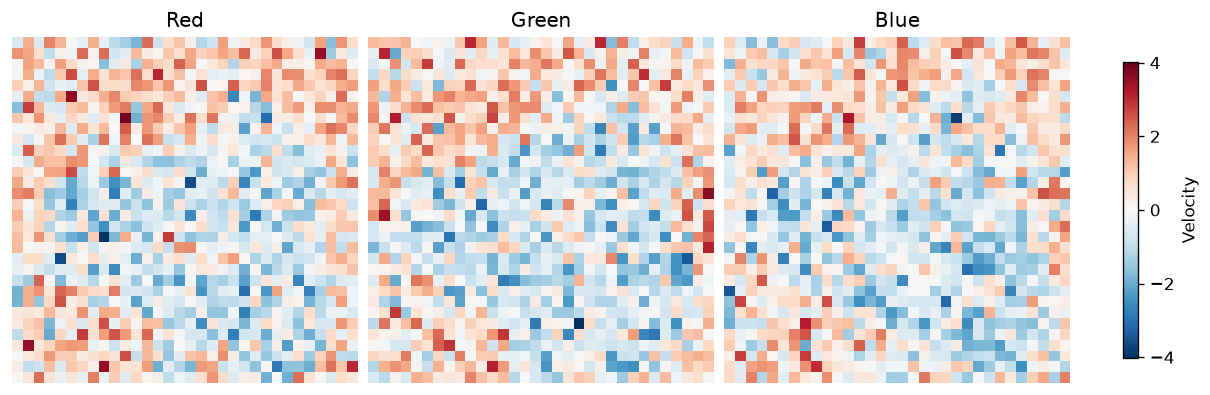

In [7]:
limit = np.abs(velocity).max()
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), layout="constrained")
for channel, (ax, name) in enumerate(zip(axes, ["Red", "Green", "Blue"])):
    im = ax.imshow(velocity[..., channel], cmap="RdBu_r",
                   vmin=-limit, vmax=limit, interpolation="nearest")
    ax.set_title(name)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, shrink=0.8, label="Velocity")
plt.show()


## PCA · all 50,000 images

$$
z=W(x-\mu),\quad WW^\top=I_2,\quad
Z_0\sim\mathcal N(-W\mu,I_2).
$$
$$
Z_t=(1-t)Z_0+tZ_1,\qquad \dot Z_t=Z_1-Z_0.
$$


In [8]:
flat = X_train.reshape(len(X_train), -1)
pca = PCA(n_components=2, svd_solver="randomized", random_state=0)
pca.fit(flat)
z1 = pca.transform(flat)
z0 = rng.standard_normal(z1.shape) - pca.mean_ @ pca.components_.T
dz = z1 - z0

print(f"Image variance retained: {100 * pca.explained_variance_ratio_.sum():.2f}%")

pooled = np.concatenate([z0, z1])
lower, upper = pooled.min(axis=0), pooled.max(axis=0)
margin = 0.04 * (upper - lower)
x_edges = np.linspace(lower[0] - margin[0], upper[0] + margin[0], 121)
y_edges = np.linspace(lower[1] - margin[1], upper[1] + margin[1], 121)
bin_area = np.diff(x_edges)[0] * np.diff(y_edges)[0]


def density(z):
    counts, _, _ = np.histogram2d(z[:, 0], z[:, 1], bins=[x_edges, y_edges])
    return gaussian_filter(counts / (len(z) * bin_area), sigma=1.5)


densities = [density((1 - ti) * z0 + ti * z1) for ti in times]


Image variance retained: 40.33%


### Projected densities

$$
\widehat p_t(z)\approx\frac{N_{B(z)}}{N\,|B(z)|}.
$$

All panels share axes, bins, smoothing, and color scale.


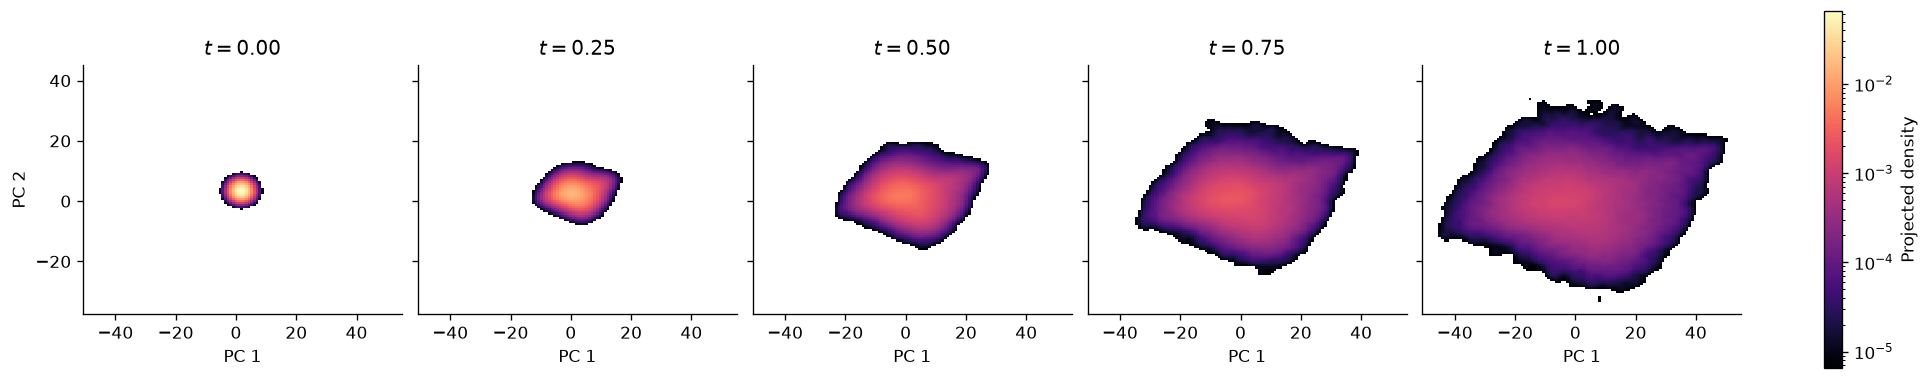

In [9]:
peak = max(h.max() for h in densities)
density_norm = LogNorm(vmin=peak * 1e-4, vmax=peak)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.8), sharex=True, sharey=True,
                         layout="constrained")
for ax, ti, h in zip(axes, times, densities):
    im = ax.pcolormesh(x_edges, y_edges, np.ma.masked_less(h.T, density_norm.vmin),
                      cmap="magma", norm=density_norm, shading="auto")
    ax.set_title(f"$t={ti:.2f}$")
    ax.set_xlabel("PC 1")
    ax.set_aspect("equal")
axes[0].set_ylabel("PC 2")
fig.colorbar(im, ax=axes, shrink=0.8, label="Projected density")
plt.show()


### Density surfaces


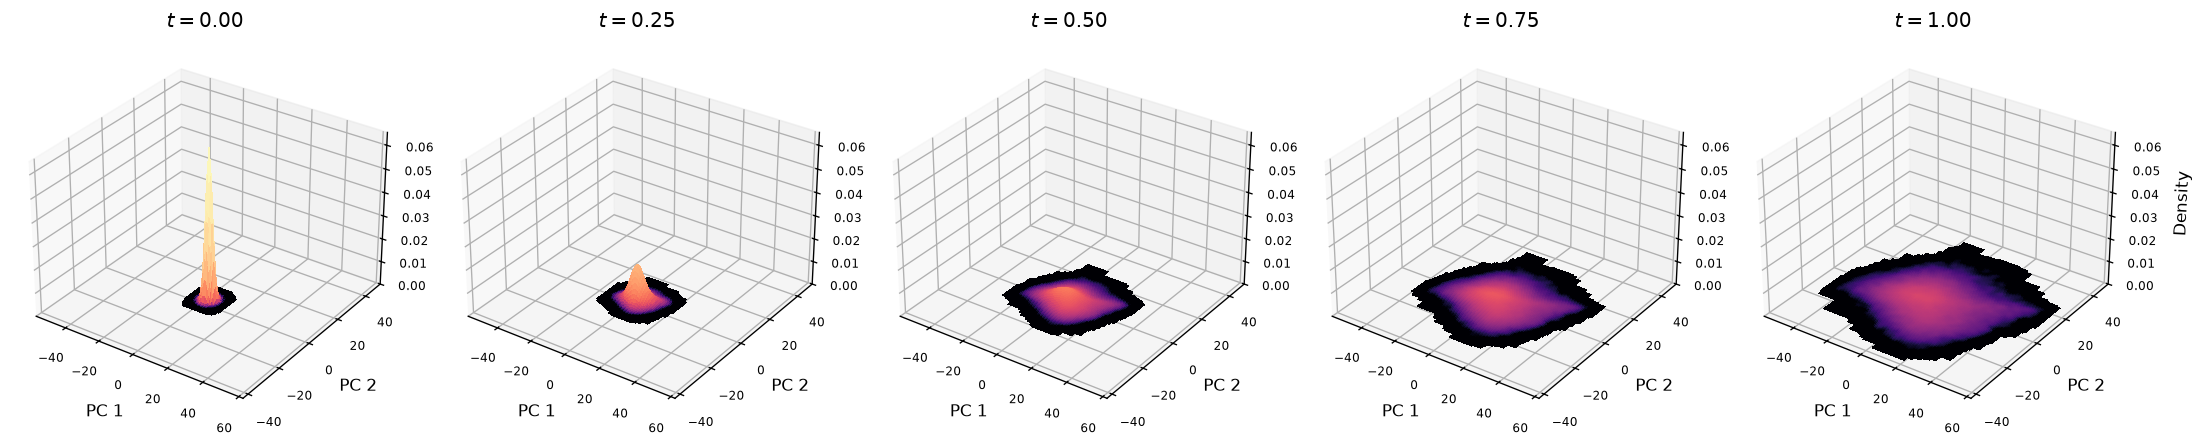

In [10]:
xc = (x_edges[:-1] + x_edges[1:]) / 2
yc = (y_edges[:-1] + y_edges[1:]) / 2
GX, GY = np.meshgrid(xc, yc)

fig, axes = plt.subplots(1, 5, figsize=(18, 4),
                         subplot_kw={"projection": "3d"}, layout="constrained")
for ax, ti, h in zip(axes, times, densities):
    ax.plot_surface(GX, GY, h.T, cmap="magma", norm=density_norm,
                    rstride=1, cstride=1, linewidth=0, antialiased=False)
    ax.set(xlabel="PC 1", ylabel="PC 2", zlabel="Density",
           title=f"$t={ti:.2f}$", zlim=(0, peak))
    ax.view_init(elev=30, azim=-55)
    ax.set_box_aspect((1, 1, 0.7))
    ax.tick_params(labelsize=7)
plt.show()

### Local target velocities

$$
\widehat u_B(t)=\frac1{N_B}\sum_{i:Z_{t,i}\in B}(Z_{1,i}-Z_{0,i}),
\qquad \text{arrow}=0.1\,\widehat u_B(t).
$$

$N_B\ge20$.


In [11]:
flow_x = np.linspace(x_edges[0], x_edges[-1], 21)
flow_y = np.linspace(y_edges[0], y_edges[-1], 21)
local_flows = []
for ti in times:
    zt = (1 - ti) * z0 + ti * z1
    count, _, _ = np.histogram2d(zt[:, 0], zt[:, 1], bins=[flow_x, flow_y])
    sum_x, _, _ = np.histogram2d(zt[:, 0], zt[:, 1], bins=[flow_x, flow_y],
                                weights=dz[:, 0])
    sum_y, _, _ = np.histogram2d(zt[:, 0], zt[:, 1], bins=[flow_x, flow_y],
                                weights=dz[:, 1])
    u = np.divide(sum_x, count, out=np.zeros_like(sum_x), where=count > 0).T
    v = np.divide(sum_y, count, out=np.zeros_like(sum_y), where=count > 0).T
    local_flows.append((u, v, count.T >= 20))


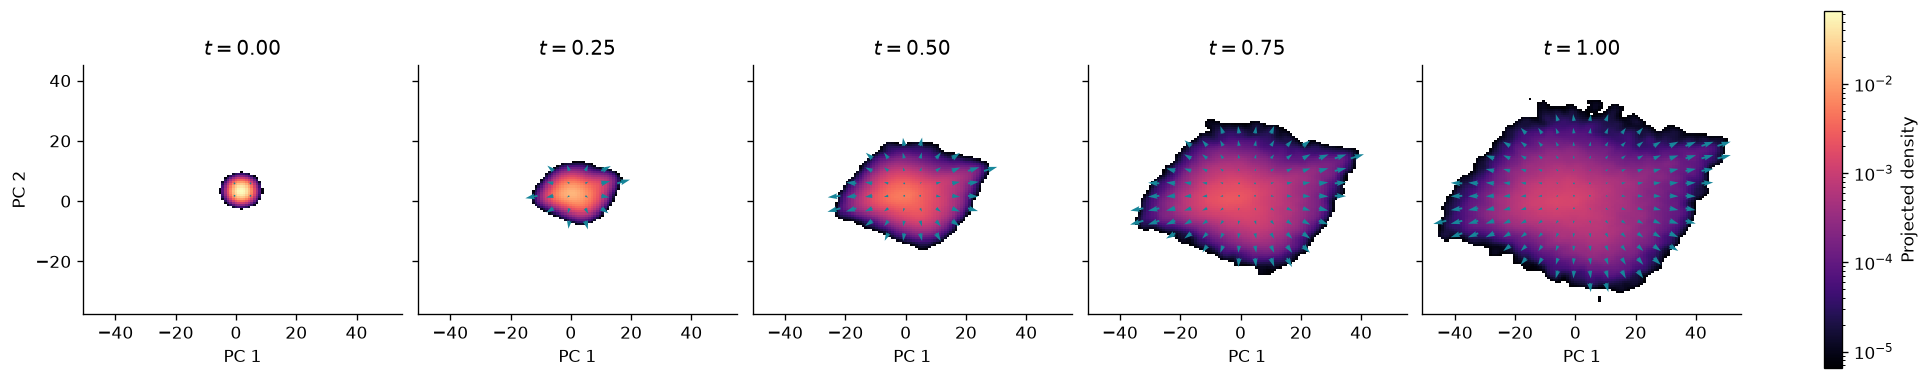

In [12]:
FX, FY = np.meshgrid((flow_x[:-1] + flow_x[1:]) / 2,
                     (flow_y[:-1] + flow_y[1:]) / 2)
dt = 0.1
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8), sharex=True, sharey=True,
                         layout="constrained")
for ax, ti, h, (u, v, keep) in zip(axes, times, densities, local_flows):
    im = ax.pcolormesh(x_edges, y_edges, np.ma.masked_less(h.T, density_norm.vmin),
                      cmap="magma", norm=density_norm, shading="auto")
    ax.quiver(FX[keep], FY[keep], dt * u[keep], dt * v[keep],
              color="#17869a", angles="xy", scale_units="xy", scale=1, width=0.006)
    ax.set(title=f"$t={ti:.2f}$", xlabel="PC 1")
    ax.set_aspect("equal")
axes[0].set_ylabel("PC 2")
fig.colorbar(im, ax=axes, shrink=0.8, label="Projected density")
plt.show()


### Classes

$$
p_c(z)=p_{Z_1\mid Y=c}(z).
$$


In [13]:
class_densities = [density(z1[y_train == c]) for c in range(10)]


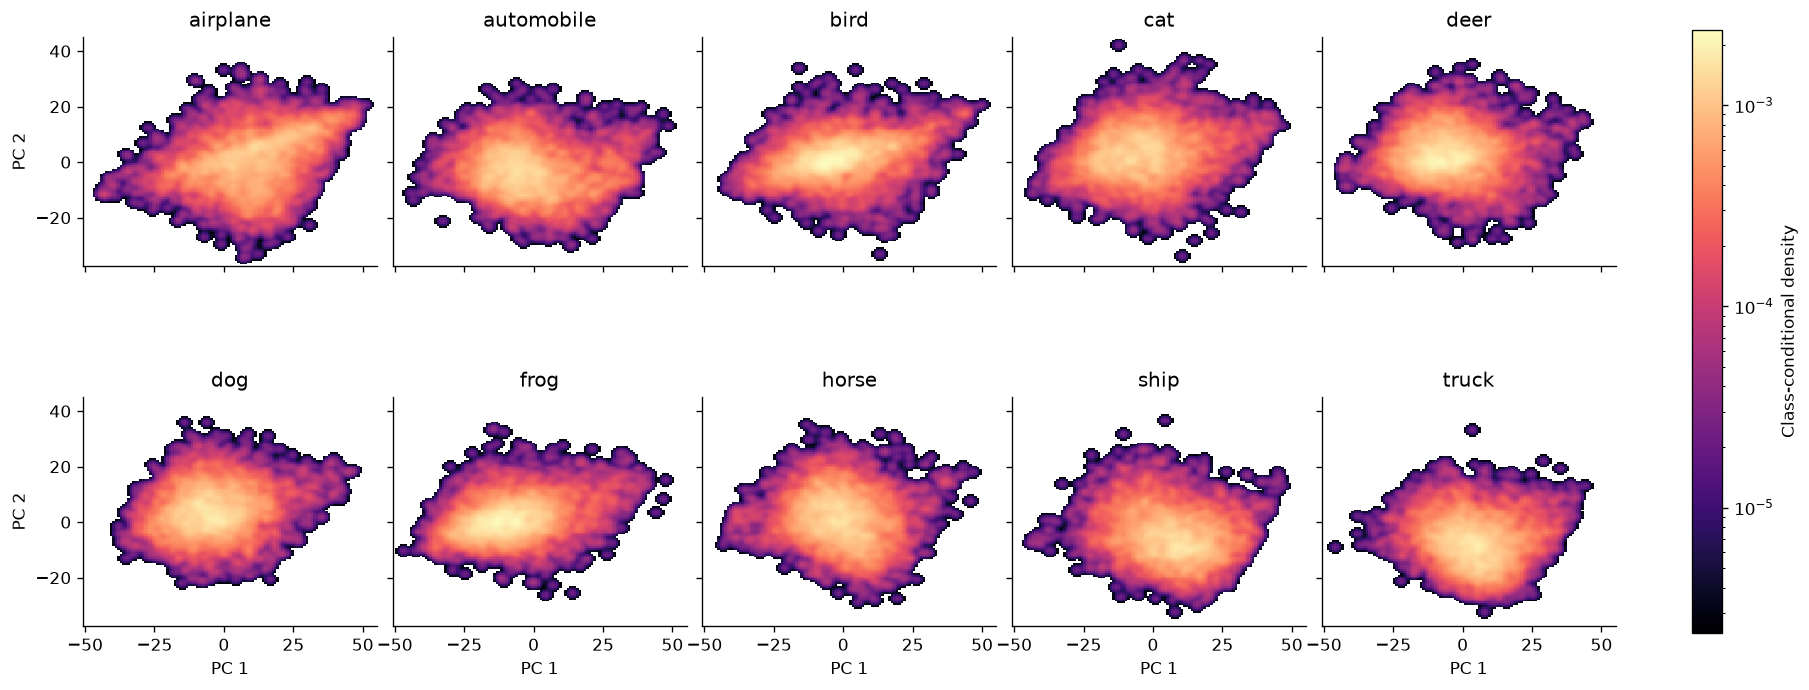

In [14]:
class_peak = max(h.max() for h in class_densities)
class_norm = LogNorm(vmin=class_peak * 1e-3, vmax=class_peak)

fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharex=True, sharey=True,
                         layout="constrained")
for c, (ax, h) in enumerate(zip(axes.flat, class_densities)):
    im = ax.pcolormesh(x_edges, y_edges, np.ma.masked_less(h.T, class_norm.vmin),
                      cmap="magma", norm=class_norm, shading="auto")
    ax.set_title(class_names[c])
    ax.set_aspect("equal")
for ax in axes[-1]:
    ax.set_xlabel("PC 1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC 2")
fig.colorbar(im, ax=axes, shrink=0.85, label="Class-conditional density")
plt.show()


## Moments · full image space

$$
\mu_t=t\mu_1,\qquad \Sigma_t=(1-t)^2I+t^2\Sigma_1.
$$
$$
m(t)=\frac1d\sum_j\mu_{t,j},\qquad
s^2(t)=\frac{\operatorname{tr}\Sigma_t}{d},\qquad d=3072.
$$


In [15]:
flat0 = np.asarray(x0).reshape(len(x0), -1)
flat1 = np.asarray(x1).reshape(len(x1), -1)
moment_times = np.linspace(0, 1, 21)
means, variances = [], []
for ti in moment_times:
    values = (1 - ti) * flat0 + ti * flat1
    means.append(values.mean())
    variances.append(values.var(axis=0).mean())

mean_prediction = moment_times * flat1.mean()
variance_prediction = (1 - moment_times)**2 + moment_times**2 * flat1.var(axis=0).mean()


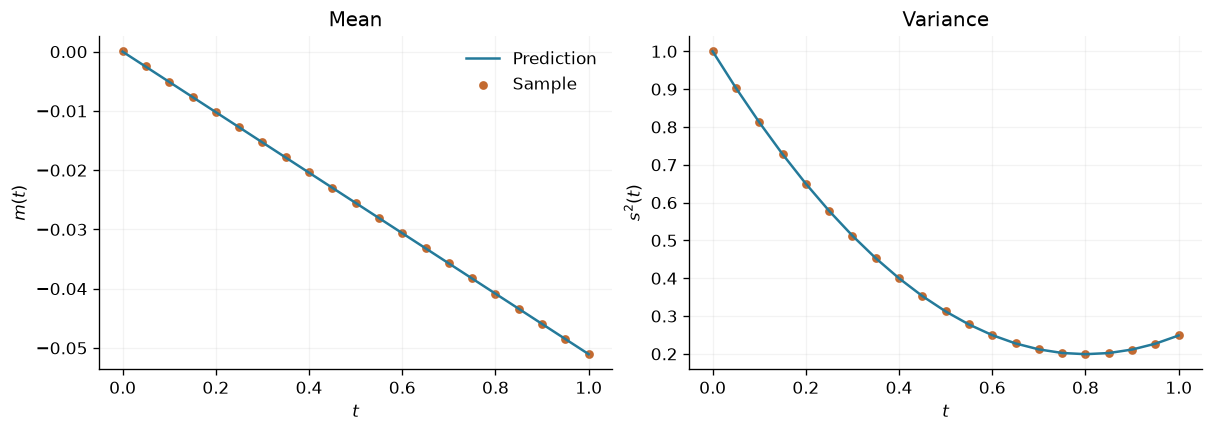

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].plot(moment_times, mean_prediction, label="Prediction", color="#247a9a")
axes[0].scatter(moment_times, means, label="Sample", color="#c36a30", s=18)
axes[0].set(xlabel="$t$", ylabel="$m(t)$", title="Mean")
axes[0].legend(frameon=False)

axes[1].plot(moment_times, variance_prediction, color="#247a9a")
axes[1].scatter(moment_times, variances, color="#c36a30", s=18)
axes[1].set(xlabel="$t$", ylabel="$s^2(t)$", title="Variance")
for ax in axes:
    ax.grid(alpha=0.15)
plt.show()


## Model

$$
v_\theta(x,t)=\operatorname{UNet}_\theta(x,e(t)),\quad
e(t)=\operatorname{MLP}_\theta
\begin{pmatrix}t\\ \sin 2\pi t\\ \cos 2\pi t\\ \sin 4\pi t\\ \cos 4\pi t\end{pmatrix}.
$$
$$
\mathcal L(\theta)=\mathbb E\!\left[\frac1d
\|v_\theta(X_T,T)-(X_1-X_0)\|^2\right],\quad
v^*(x,t)=\mathbb E[X_1-X_0\mid X_t=x].
$$


In [17]:
batch_size = 128
max_epochs = 50
patience = 5
min_delta = 1e-3
lr = 2e-4


def loss_fn(params, xt, t, target):
    prediction = model_apply(params, xt, t)
    return jnp.mean((prediction - target)**2)


@jax.jit
def train_step(params, m, v_adam, xt, t, target, step):
    loss, grads = jax.value_and_grad(loss_fn)(params, xt, t, target)
    m = jax.tree_util.tree_map(lambda a, g: 0.9 * a + 0.1 * g, m, grads)
    v_adam = jax.tree_util.tree_map(
        lambda a, g: 0.999 * a + 0.001 * g**2, v_adam, grads
    )
    params = jax.tree_util.tree_map(
        lambda p, a, b: p - lr * (a / (1 - 0.9**step))
        / (jnp.sqrt(b / (1 - 0.999**step)) + 1e-8),
        params, m, v_adam
    )
    return params, m, v_adam, loss


eval_loss = jax.jit(loss_fn)


### Initialization

1,024 fixed validation pairs.


In [18]:
key, model_key = jax.random.split(jax.random.key(1))
params = init_model(model_key)
m = jax.tree_util.tree_map(jnp.zeros_like, params)
v_adam = jax.tree_util.tree_map(jnp.zeros_like, params)
step = 0
train_rng = np.random.default_rng(1)

split = np.random.default_rng(2).permutation(len(X_train))
val_indices, train_indices = split[:1024], split[1024:]
val_images = jnp.asarray(X_train[val_indices])
_, val_xt, val_t, val_target = make_flow_batch(val_images, jax.random.key(2))


def validation_loss(params):
    losses = [float(eval_loss(params, val_xt[i:i + batch_size],
                              val_t[i:i + batch_size], val_target[i:i + batch_size]))
              for i in range(0, len(val_images), batch_size)]
    return float(np.mean(losses))


zero_mse = float(jnp.mean(val_target**2))
train_losses = []
val_losses = [validation_loss(params)]
if not np.isfinite(val_losses[0]):
    raise FloatingPointError("Non-finite initial validation loss.")
best_loss = patience_loss = val_losses[0]
best_state = (params, m, v_adam, step)
best_epoch = 0
stale_epochs = 0


### Training · Adam


In [19]:
for epoch in range(max_epochs):
    order = train_rng.permutation(train_indices)
    epoch_loss = 0.0
    batches = len(train_indices) // batch_size

    for start in range(0, batches * batch_size, batch_size):
        step += 1
        batch = jnp.asarray(X_train[order[start:start + batch_size]])
        key, batch_key = jax.random.split(key)
        _, batch_xt, batch_t, batch_target = make_flow_batch(batch, batch_key)
        params, m, v_adam, loss = train_step(
            params, m, v_adam, batch_xt, batch_t, batch_target, step
        )
        epoch_loss += loss

    train_losses.append(float(epoch_loss / batches))
    val_losses.append(validation_loss(params))
    current_loss = val_losses[-1]
    print(f"{epoch + 1:3d} | train {train_losses[-1]:.5f} | validation {current_loss:.5f}")

    if not np.isfinite(train_losses[-1]) or not np.isfinite(current_loss):
        params, m, v_adam, step = best_state
        raise FloatingPointError("Non-finite loss; best training state restored.")

    if current_loss < best_loss:
        best_loss = current_loss
        best_state = (params, m, v_adam, step)
        best_epoch = epoch + 1

    if current_loss < patience_loss - min_delta:
        patience_loss = current_loss
        stale_epochs = 0
    else:
        stale_epochs += 1

    if stale_epochs >= patience:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

params, m, v_adam, step = best_state
print(f"Restored epoch {best_epoch} | validation {best_loss:.5f}")


  1 | train 0.47709 | validation 0.28443


  2 | train 0.26770 | validation 0.24938


  3 | train 0.24662 | validation 0.23450


  4 | train 0.23429 | validation 0.22528


  5 | train 0.22812 | validation 0.22009


  6 | train 0.22143 | validation 0.21449


... (21 outputs left out)

 28 | train 0.19200 | validation 0.18990


 29 | train 0.19062 | validation 0.18855


 30 | train 0.19051 | validation 0.18945


 31 | train 0.19058 | validation 0.18826
Early stopping at epoch 31.
Restored epoch 31 | validation 0.18826


### Loss


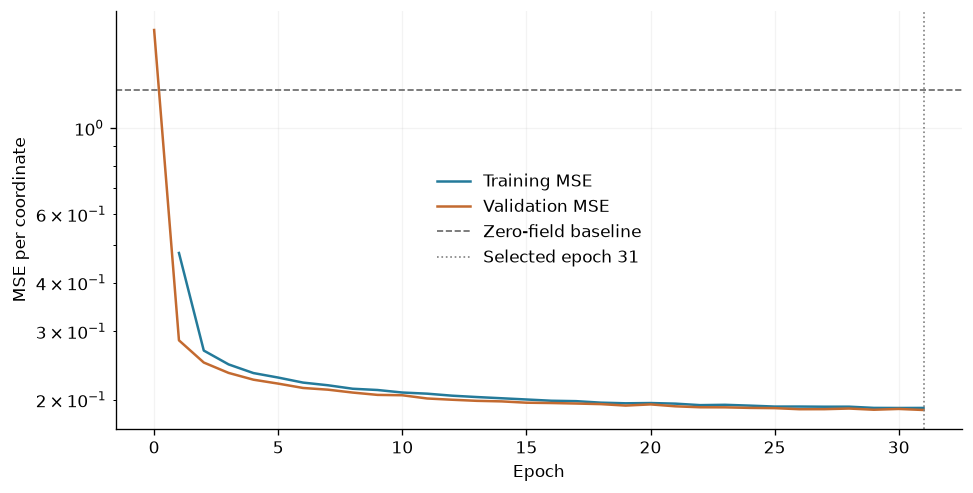

In [20]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(np.arange(1, len(train_losses) + 1), train_losses,
        color="#247a9a", label="Training MSE")
ax.plot(np.arange(len(val_losses)), val_losses,
        color="#c36a30", label="Validation MSE")
ax.axhline(zero_mse, color="0.4", ls="--", lw=1, label="Zero-field baseline")
ax.axvline(best_epoch, color="0.5", ls=":", lw=1,
           label=f"Selected epoch {best_epoch}")
ax.set(xlabel="Epoch", ylabel="MSE per coordinate", yscale="log")
ax.grid(alpha=0.15)
ax.legend(frameon=False)
plt.show()


## Trained generation

$$
\dot x=v_\theta(x,t),\quad x(0)\sim\mathcal N(0,I),\qquad
x_{k+1}=x_k+h\,v_\theta(x_k,kh),\quad h=\frac1{64}.
$$


In [21]:
n_generated = 512
sample_batch = 64
n_steps = 64
sample_times = np.linspace(0, 1, n_steps + 1)


@partial(jax.jit, static_argnames=("steps",))
def integrate(params, initial, steps=64):
    def advance(x, k):
        t = jnp.full((len(x), 1, 1, 1), k / steps)
        next_x = x + model_apply(params, x, t) / steps
        return next_x, next_x

    _, states = jax.lax.scan(advance, initial, jnp.arange(steps))
    return jnp.concatenate([initial[None], states], axis=0)


generated_batches, projected_batches = [], []
sample_keys = jax.random.split(jax.random.key(3), n_generated // sample_batch)
for i, sample_key in enumerate(sample_keys):
    initial = jax.random.normal(sample_key, (sample_batch, 32, 32, 3))
    path = np.asarray(integrate(params, initial, steps=n_steps))
    assert np.isfinite(path).all(), "Non-finite generated trajectory."
    generated_batches.append(path[-1].copy())
    projected_batches.append(
        pca.transform(path.reshape(-1, 3072)).reshape(n_steps + 1, sample_batch, 2)
    )
    if i == 0:
        image_path = path[:, :16].copy()

generated = np.concatenate(generated_batches)
z_path = np.concatenate(projected_batches, axis=1)
z_generated = z_path[-1]
del path

test_indices = np.random.default_rng(4).choice(len(data["test"]), n_generated,
                                               replace=False)
real = np.stack([np.asarray(img) for img in data["test"][test_indices.tolist()]["img"]])
real = real.astype(np.float32) / 127.5 - 1
z_real = pca.transform(real.reshape(n_generated, -1))

remaining_indices = np.setdiff1d(np.arange(len(data["test"])), test_indices)
reference_indices = np.random.default_rng(6).choice(remaining_indices, n_generated,
                                                    replace=False)
real_b = np.stack([np.asarray(img) for img in data["test"][reference_indices.tolist()]["img"]])
real_b = real_b.astype(np.float32) / 127.5 - 1
z_real_b = pca.transform(real_b.reshape(n_generated, -1))

comparison_points = np.concatenate([z_real, z_real_b, z_path.reshape(-1, 2)])
lo, hi = comparison_points.min(axis=0), comparison_points.max(axis=0)
padding = 0.04 * (hi - lo)
compare_x = np.linspace(lo[0] - padding[0], hi[0] + padding[0], 41)
compare_y = np.linspace(lo[1] - padding[1], hi[1] + padding[1], 41)
compare_area = np.diff(compare_x)[0] * np.diff(compare_y)[0]


def projected_density(z):
    counts, _, _ = np.histogram2d(z[:, 0], z[:, 1], bins=[compare_x, compare_y])
    return gaussian_filter(counts / (len(z) * compare_area), sigma=1.0)


p_real = projected_density(z_real)
p_real_b = projected_density(z_real_b)
p_generated = projected_density(z_generated)
outside = np.mean((generated < -1) | (generated > 1))
print(f"Generated coordinates outside [-1, 1]: {100 * outside:.2f}%")


Generated coordinates outside [-1, 1]: 0.73%


### Real and generated · 16 images each


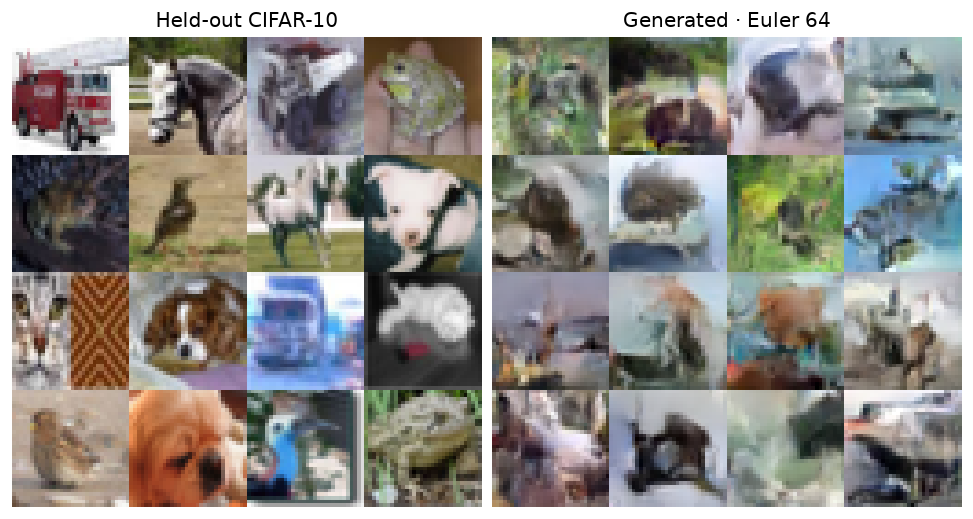

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout="constrained")
for ax, images, title in zip(axes, [real[:16], generated[:16]],
                              ["Held-out CIFAR-10", "Generated · Euler 64"]):
    ax.imshow(image_grid(images), interpolation="nearest")
    ax.set_title(title)
    ax.set_axis_off()
plt.show()


### Learned trajectories

$$
z_k=W(x_k-\mu),\qquad \dot z_k=Wv_\theta(x_k,t_k).
$$

Paths are integrated in image space, then projected.


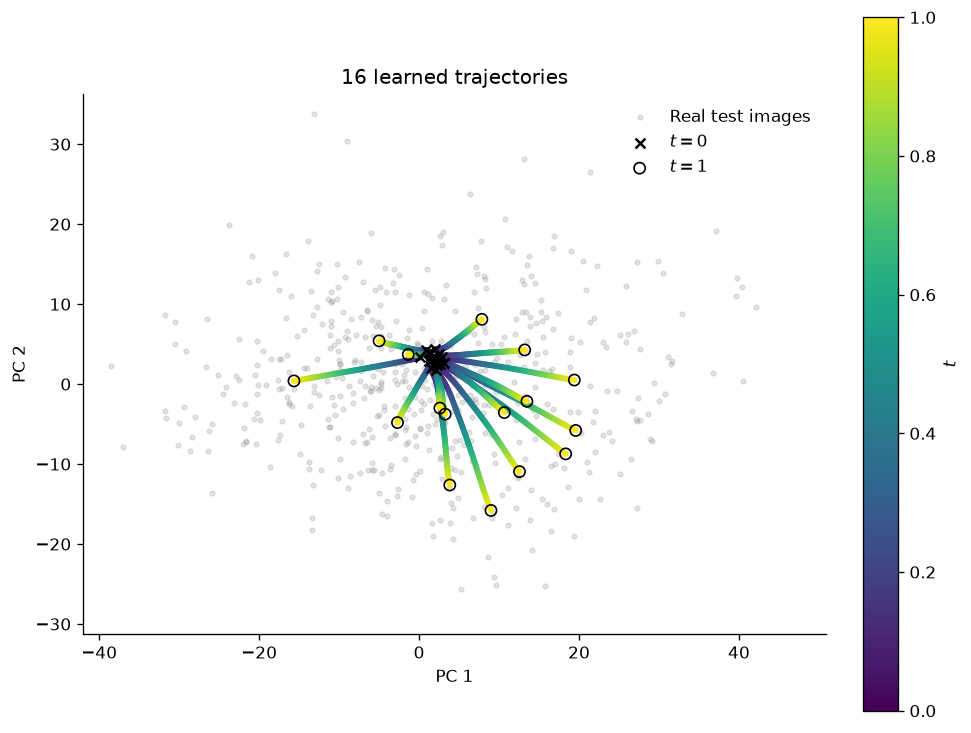

In [23]:
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.scatter(z_real[:, 0], z_real[:, 1], color="0.5", s=8, alpha=0.2,
           label="Real test images")
for i in range(16):
    ax.plot(z_path[:, i, 0], z_path[:, i, 1], color="#247a9a", lw=1, alpha=0.65)

points = z_path[:, :16].reshape(-1, 2)
im = ax.scatter(points[:, 0], points[:, 1], c=np.repeat(sample_times, 16),
                cmap="viridis", s=7, zorder=3)
ax.scatter(z_path[0, :16, 0], z_path[0, :16, 1], marker="x",
           color="black", s=35, label="$t=0$", zorder=4)
ax.scatter(z_path[-1, :16, 0], z_path[-1, :16, 1], marker="o",
           facecolors="none", edgecolors="black", s=45, label="$t=1$", zorder=4)
ax.set(xlabel="PC 1", ylabel="PC 2", title="16 learned trajectories",
       xlim=(compare_x[0], compare_x[-1]), ylim=(compare_y[0], compare_y[-1]))
ax.set_aspect("equal")
ax.legend(frameon=False)
fig.colorbar(im, ax=ax, label="$t$")
plt.show()

### One sample through the density landscape

$$
z_t=W(x_t-\mu),\qquad
\ell_t(z)=\log_{10}\max\{\widehat p_{\theta,Z,t}(z),\varepsilon\}.
$$


In [24]:
landscape_densities = np.stack([projected_density(points) for points in z_path])
landscape_floor = landscape_densities.max() * 1e-4
landscape_heights = np.log10(np.maximum(landscape_densities, landscape_floor))
landscape_x = (compare_x[:-1] + compare_x[1:]) / 2
landscape_y = (compare_y[:-1] + compare_y[1:]) / 2
landscape_coordinates = np.vstack([
    (z_path[:, 0, 0] - landscape_x[0]) / np.diff(compare_x)[0],
    (z_path[:, 0, 1] - landscape_y[0]) / np.diff(compare_y)[0],
])
landscape_trails = [
    map_coordinates(height, landscape_coordinates[:, :k + 1], order=1, mode="nearest")
    for k, height in enumerate(landscape_heights)
]


In [25]:
LX, LY = np.meshgrid(landscape_x, landscape_y)
height_min, height_max = landscape_heights.min(), landscape_heights.max()
point_offset = 0.015 * (height_max - height_min)

fig = plt.figure(figsize=(11, 4.8), dpi=85, layout="constrained")
landscape_ax = fig.add_subplot(1, 2, 1, projection="3d", computed_zorder=False)
image_ax = fig.add_subplot(1, 2, 2)
landscape_surface = landscape_ax.plot_surface(
    LX, LY, landscape_heights[0].T, cmap="magma", vmin=height_min, vmax=height_max,
    rstride=1, cstride=1, linewidth=0, antialiased=False, shade=False, zorder=1
)
trail_artist, = landscape_ax.plot([], [], [], color="#59e1db", lw=2, zorder=3)
point_artist, = landscape_ax.plot(
    [z_path[0, 0, 0]], [z_path[0, 0, 1]], [landscape_trails[0][-1] + point_offset],
    marker="o", ms=8, color="#59e1db", markeredgecolor="white", zorder=4
)
landscape_ax.set(
    xlabel="PC 1", ylabel="PC 2", zlabel=r"$\log_{10}\widehat p_t$",
    title="Sample 1 through PCA density",
    xlim=(compare_x[0], compare_x[-1]), ylim=(compare_y[0], compare_y[-1]),
    zlim=(height_min, height_max + 2 * point_offset)
)
landscape_ax.view_init(elev=30, azim=-55)
landscape_ax.set_box_aspect((1, 1, 0.65))
landscape_ax.tick_params(labelsize=8)
image_artist = image_ax.imshow(rgb(image_path[0, 0]), interpolation="nearest")
image_ax.set_title("Sample 1")
image_ax.set_axis_off()
time_title = fig.suptitle("$t=0.00$")


def animate_landscape(k):
    global landscape_surface
    landscape_surface.remove()
    landscape_surface = landscape_ax.plot_surface(
        LX, LY, landscape_heights[k].T, cmap="magma", vmin=height_min, vmax=height_max,
        rstride=1, cstride=1, linewidth=0, antialiased=False, shade=False, zorder=1
    )
    trail_artist.set_data_3d(z_path[:k + 1, 0, 0], z_path[:k + 1, 0, 1],
                             landscape_trails[k] + point_offset)
    point_artist.set_data_3d([z_path[k, 0, 0]], [z_path[k, 0, 1]],
                             [landscape_trails[k][-1] + point_offset])
    image_artist.set_data(rgb(image_path[k, 0]))
    time_title.set_text(f"$t={sample_times[k]:.2f}$")
    return landscape_surface, trail_artist, point_artist, image_artist, time_title


generation_animation = FuncAnimation(
    fig, animate_landscape, frames=range(0, n_steps + 1, 2),
    interval=160, repeat=True, blit=False
)
plt.close(fig)
display(HTML(generation_animation.to_jshtml()))


### PCA density · generated and real

$$
\widehat p_{\theta,Z}(z),\qquad \widehat p_{\mathrm{data},Z}(z),\qquad
\Delta p(z)=\widehat p_{\theta,Z}(z)-\widehat p_{\mathrm{data},Z}(z).
$$


In [26]:
difference = p_generated - p_real
real_marginals = [np.histogram(z_real[:, j], bins=edges, density=True)[0]
                  for j, edges in enumerate([compare_x, compare_y])]
generated_marginals = [np.histogram(z_generated[:, j], bins=edges, density=True)[0]
                       for j, edges in enumerate([compare_x, compare_y])]


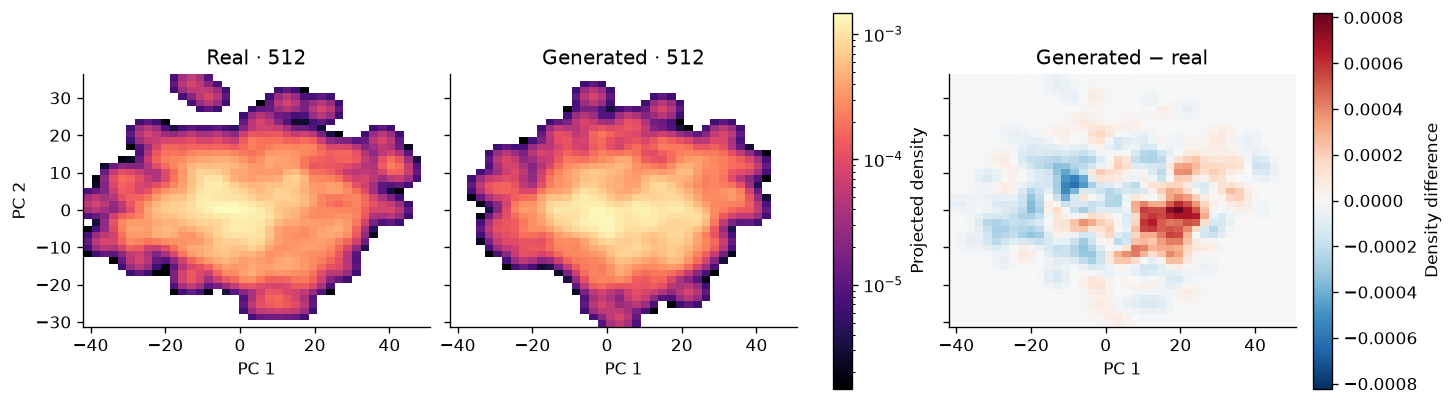

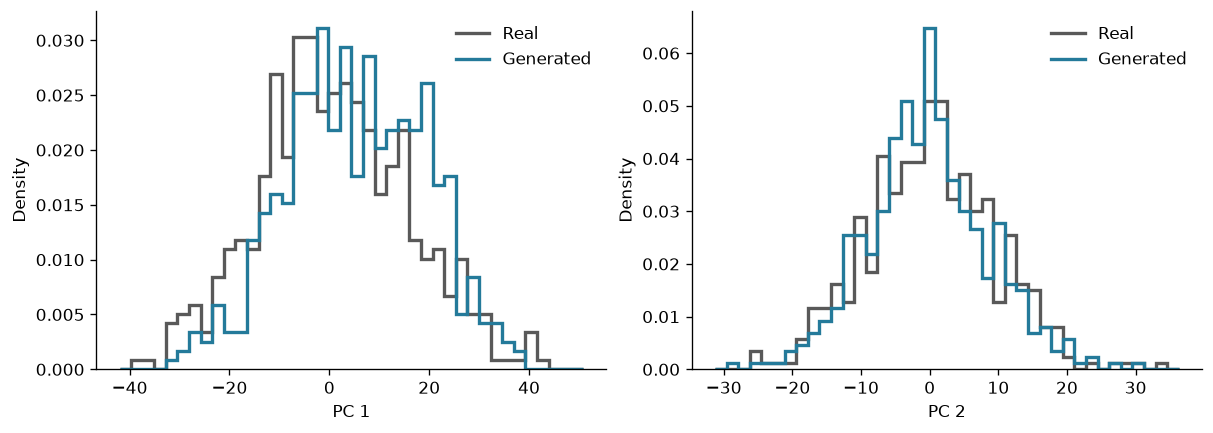

In [27]:
comparison_peak = max(p_real.max(), p_generated.max())
comparison_norm = LogNorm(vmin=comparison_peak * 1e-3, vmax=comparison_peak)
difference_limit = np.abs(difference).max()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True,
                         layout="constrained")
for ax, h, title in zip(axes[:2], [p_real, p_generated], ["Real · 512", "Generated · 512"]):
    im = ax.pcolormesh(compare_x, compare_y,
                      np.ma.masked_less(h.T, comparison_norm.vmin),
                      cmap="magma", norm=comparison_norm, shading="auto")
    ax.set_title(title)
residual = axes[2].pcolormesh(compare_x, compare_y, difference.T,
                             cmap="RdBu_r", vmin=-difference_limit,
                             vmax=difference_limit, shading="auto")
axes[2].set_title("Generated − real")
for ax in axes:
    ax.set_xlabel("PC 1")
    ax.set_aspect("equal")
axes[0].set_ylabel("PC 2")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="Projected density")
fig.colorbar(residual, ax=axes[2], shrink=0.8, label="Density difference")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for j, (ax, edges) in enumerate(zip(axes, [compare_x, compare_y])):
    ax.stairs(real_marginals[j], edges, lw=2, color="0.35", label="Real")
    ax.stairs(generated_marginals[j], edges, lw=2, color="#247a9a", label="Generated")
    ax.set(xlabel=f"PC {j + 1}", ylabel="Density")
    ax.legend(frameon=False)
plt.show()


### Distribution evolution

$$
\dot X^\theta_t=v_\theta(X^\theta_t,t),\qquad
X_t=(1-t)X_0+tX_1.
$$

Independent held-out endpoints define the linear target.


In [28]:
frame_indices = np.linspace(0, n_steps, 5, dtype=int)
model_densities = [projected_density(z_path[k]) for k in frame_indices]
target_densities = [
    projected_density((1 - sample_times[k]) * z_path[0] + sample_times[k] * z_real)
    for k in frame_indices
]


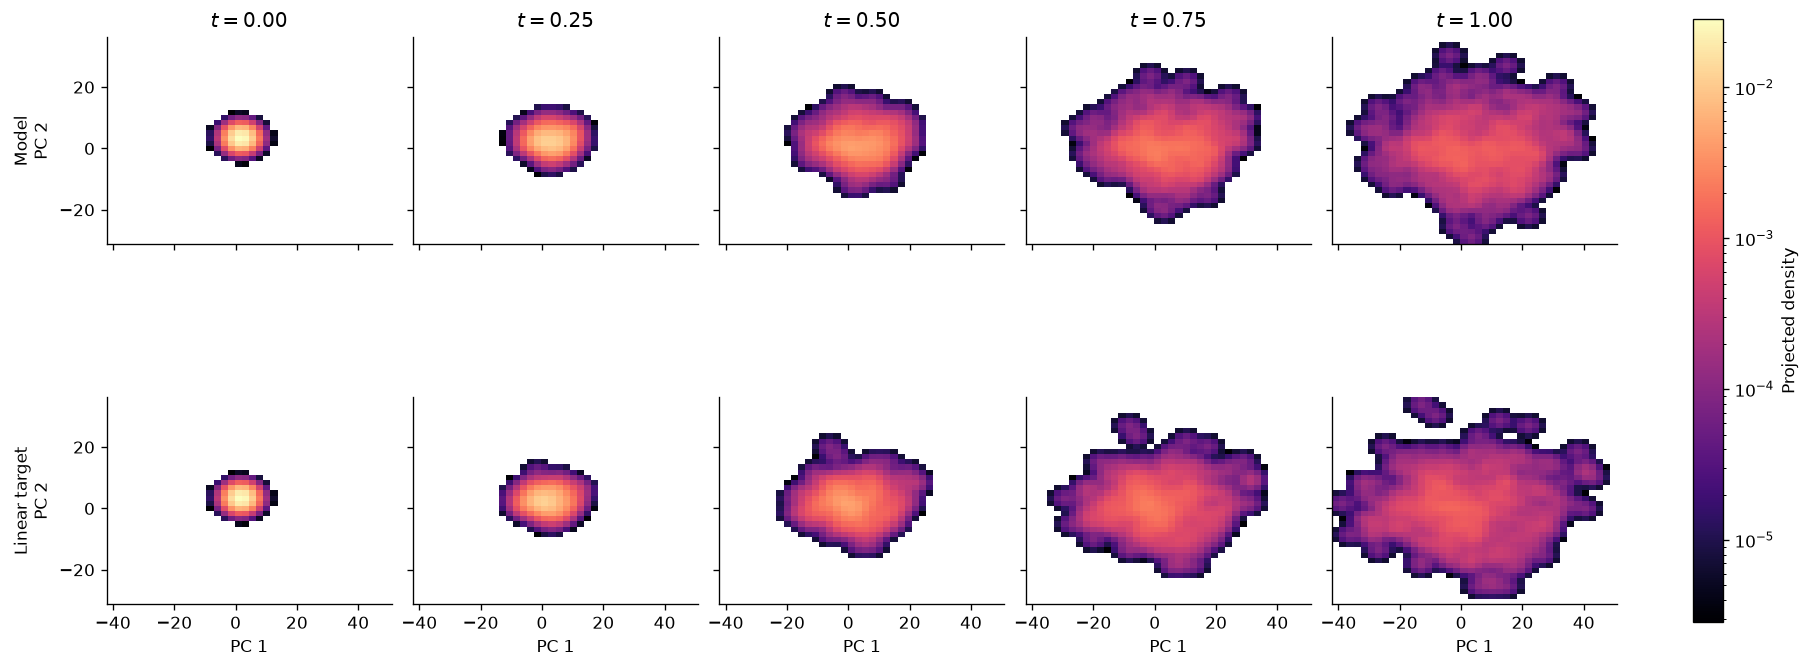

In [29]:
evolution_peak = max(h.max() for h in model_densities + target_densities)
evolution_norm = LogNorm(vmin=evolution_peak * 1e-4, vmax=evolution_peak)

fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharex=True, sharey=True,
                         layout="constrained")
for row, distributions in enumerate([model_densities, target_densities]):
    for col, (k, h) in enumerate(zip(frame_indices, distributions)):
        ax = axes[row, col]
        im = ax.pcolormesh(compare_x, compare_y,
                          np.ma.masked_less(h.T, evolution_norm.vmin),
                          cmap="magma", norm=evolution_norm, shading="auto")
        ax.set_aspect("equal")
        if row == 0:
            ax.set_title(f"$t={sample_times[k]:.2f}$")
        else:
            ax.set_xlabel("PC 1")
axes[0, 0].set_ylabel("Model\nPC 2")
axes[1, 0].set_ylabel("Linear target\nPC 2")
fig.colorbar(im, ax=axes, shrink=0.85, label="Projected density")
plt.show()


### Euler resolution

$$
e_N^{(i)}=\sqrt{\frac1d\|x_N^{(i)}-x_{256}^{(i)}\|^2}.
$$

Sixteen fixed seeds; error maps show sample 1 against the 256-step reference.


In [30]:
solver_steps = np.array([2, 4, 8, 16, 32, 64, 128, 256])
solver_initial = jnp.asarray(image_path[0])
solver_images = np.stack([
    image_path[-1] if steps == 64
    else np.asarray(integrate(params, solver_initial, steps=int(steps))[-1])
    for steps in solver_steps
])
solver_errors = solver_images[:-1] - solver_images[-1]
solver_rmse = np.sqrt(np.mean(solver_errors**2, axis=(2, 3, 4)))
solver_median = np.median(solver_rmse, axis=1)
solver_pixel_error = np.sqrt(np.mean(solver_errors[:, 0]**2, axis=-1))
solver_display = [0, 1, 2, 3, 5]


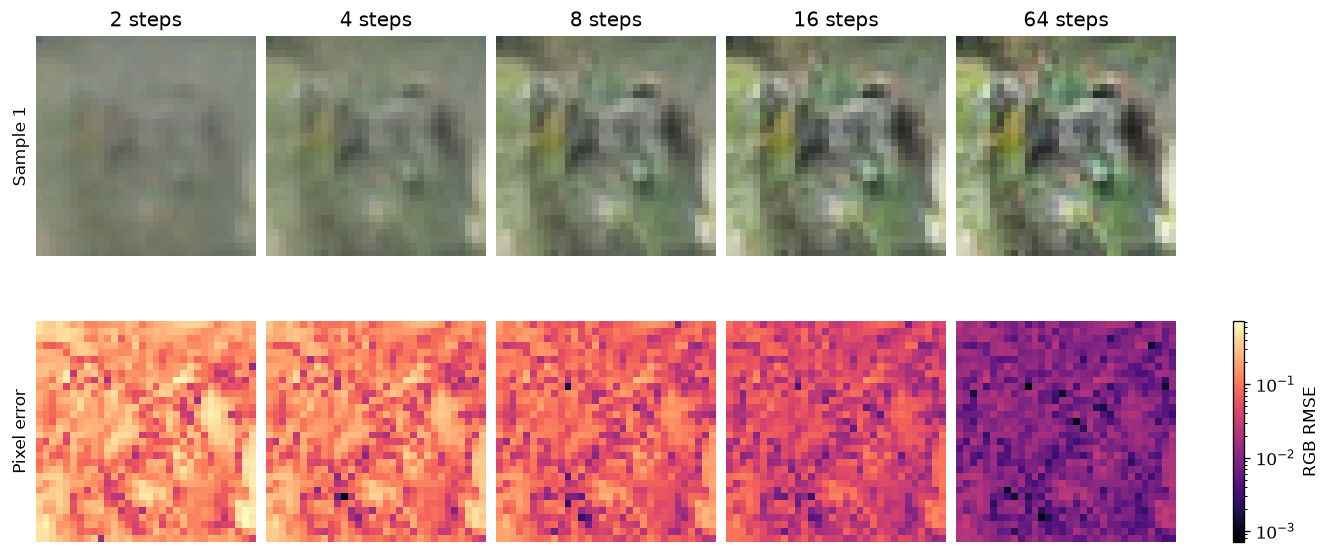

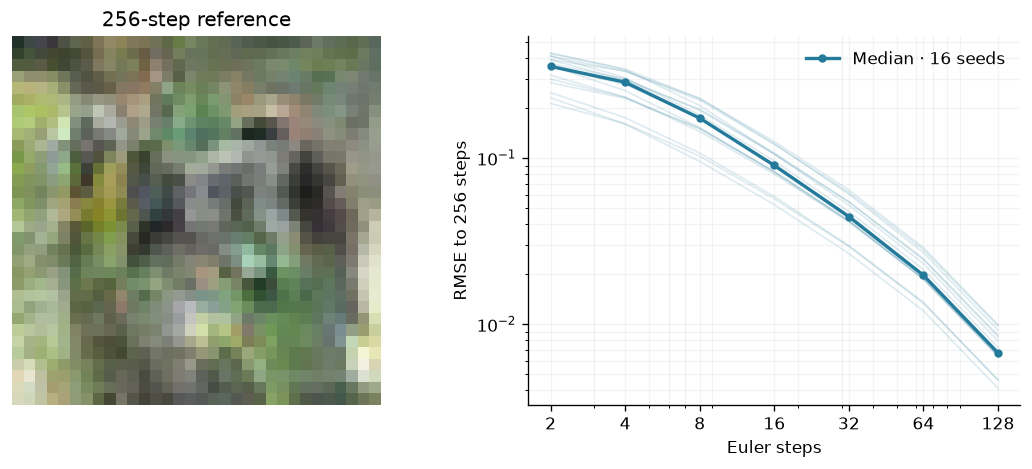

In [31]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8), layout="constrained")
error_limit = solver_pixel_error[solver_display].max()
error_norm = LogNorm(vmin=error_limit * 1e-3, vmax=error_limit)
for col, i in enumerate(solver_display):
    axes[0, col].imshow(rgb(solver_images[i, 0]), interpolation="nearest")
    axes[0, col].set_title(f"{solver_steps[i]} steps")
    im = axes[1, col].imshow(np.maximum(solver_pixel_error[i], error_norm.vmin),
                              cmap="magma", norm=error_norm, interpolation="nearest")
    for ax in axes[:, col]:
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
axes[0, 0].set_ylabel("Sample 1")
axes[1, 0].set_ylabel("Pixel error")
fig.colorbar(im, ax=axes[1], shrink=0.8, label="RGB RMSE")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
axes[0].imshow(rgb(solver_images[-1, 0]), interpolation="nearest")
axes[0].set_title("256-step reference")
axes[0].set_axis_off()
axes[1].loglog(solver_steps[:-1], solver_rmse, color="#247a9a", alpha=0.15, lw=1)
axes[1].loglog(solver_steps[:-1], solver_median,
               "o-", color="#247a9a", lw=2, ms=4, label="Median · 16 seeds")
axes[1].set(xlabel="Euler steps", ylabel="RMSE to 256 steps",
             xticks=solver_steps[:-1], xticklabels=solver_steps[:-1])
axes[1].grid(alpha=0.15, which="both")
axes[1].legend(frameon=False)
plt.show()


### Loss versus time

$$
\widehat L(t)=\frac1{nd}\sum_i
\|v_\theta((1-t)x_{0,i}+tx_{1,i},t)-(x_{1,i}-x_{0,i})\|^2.
$$
$$
L^*(0)=\frac{\operatorname{tr}\Sigma_1}{d},\qquad L^*(1)=1.
$$


In [32]:
@jax.jit
def errors_at_time(params, noise, images, ti):
    t_batch = jnp.full((len(images), 1, 1, 1), ti, dtype=images.dtype)
    states = (1 - t_batch) * noise + t_batch * images
    errors = model_apply(params, states, t_batch) - (images - noise)
    return jnp.mean(errors**2, axis=(1, 2, 3))


eval_images = np.stack([np.asarray(img) for img in data["test"][:128]["img"]])
eval_images = jnp.asarray(eval_images, dtype=jnp.float32) / 127.5 - 1
loss_times = np.linspace(0, 1, 21)
time_noise = jax.random.normal(jax.random.key(5), eval_images.shape)
time_errors = np.stack([
    np.asarray(errors_at_time(params, time_noise, eval_images, ti))
    for ti in loss_times
])
time_loss_mean = time_errors.mean(axis=1)
time_loss_se = time_errors.std(axis=1, ddof=1) / np.sqrt(len(eval_images))
endpoint_references = [np.asarray(eval_images).var(axis=0, ddof=1).mean(), 1.0]


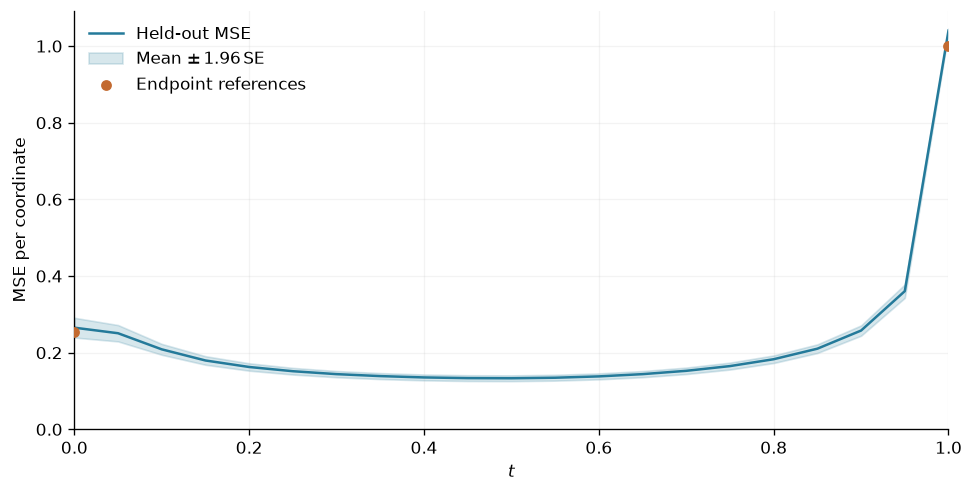

In [33]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(loss_times, time_loss_mean, color="#247a9a", label="Held-out MSE")
ax.fill_between(loss_times, np.maximum(0, time_loss_mean - 1.96 * time_loss_se),
                time_loss_mean + 1.96 * time_loss_se, color="#247a9a", alpha=0.18,
                label=r"Mean $\pm\,1.96\,\mathrm{SE}$")
ax.scatter([0, 1], endpoint_references, marker="o", s=30, color="#c36a30",
           zorder=4, label="Endpoint references")
ax.set(xlabel="$t$", ylabel="MSE per coordinate", xlim=(0, 1), ylim=(0, None))
ax.grid(alpha=0.15)
ax.legend(frameon=False)
plt.show()


### Real-versus-real density reference

$$
D(\widehat p,\widehat q)=\frac12\sum_B
|\widehat p_B-\widehat q_B|\,|B|.
$$

Real A and real B are disjoint batches of 512 images.


In [34]:
reference_difference = p_real_b - p_real
model_difference = p_generated - p_real
density_distances = 0.5 * compare_area * np.array([
    np.abs(reference_difference).sum(), np.abs(model_difference).sum()
])


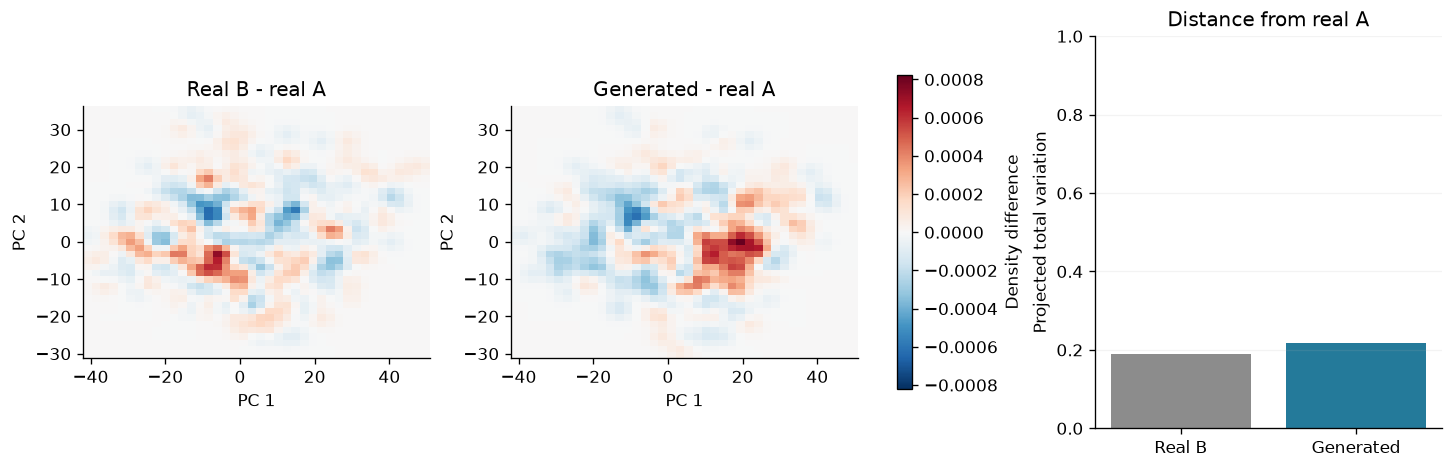

In [35]:
residual_limit = max(np.abs(reference_difference).max(), np.abs(model_difference).max(),
                     np.finfo(float).eps)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for ax, residual, title in zip(axes[:2], [reference_difference, model_difference],
                                ["Real B - real A", "Generated - real A"]):
    im = ax.pcolormesh(compare_x, compare_y, residual.T, cmap="RdBu_r",
                      vmin=-residual_limit, vmax=residual_limit, shading="auto")
    ax.set(xlabel="PC 1", ylabel="PC 2", title=title)
    ax.set_aspect("equal")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="Density difference")
axes[2].bar(["Real B", "Generated"], density_distances, color=["0.55", "#247a9a"])
axes[2].set(ylabel="Projected total variation", title="Distance from real A", ylim=(0, 1))
axes[2].grid(axis="y", alpha=0.15)
plt.show()


### Variation and texture

$$
C=\frac{(X-\bar X)^\top(X-\bar X)}{n-1},\qquad
P(r)=\left\langle|\mathcal F(x-\bar x)|^2\right\rangle_{\|\omega\|\in[r,r+1)}.
$$


In [36]:
spectra, radial_power = [], []
frequency = np.fft.fftfreq(32) * 32
radius = np.floor(np.hypot(frequency[:, None], frequency[None, :])).astype(int)
frequency_bins = np.arange(1, 17)
for images in [real, real_b, generated]:
    values = images.reshape(len(images), -1).astype(np.float64)
    centered = values - values.mean(axis=0)
    gram = centered @ centered.T / (len(images) - 1)
    spectra.append(np.maximum(np.linalg.eigvalsh(gram)[::-1], 0) / values.shape[1])
    spatial_centered = images - images.mean(axis=(1, 2), keepdims=True)
    power = np.abs(np.fft.fft2(spatial_centered, axes=(1, 2), norm="ortho"))**2
    power = power.mean(axis=(0, 3))
    radial_power.append([power[radius == r].mean() for r in frequency_bins])
spectra, radial_power = np.asarray(spectra), np.asarray(radial_power)
spectrum_ratios = spectra[:, :200] / spectra[:2, :200].mean(axis=0)
power_ratios = radial_power / radial_power[:2].mean(axis=0)
ratio_bounds = [(ratios[:2].min(axis=0), ratios[:2].max(axis=0))
                for ratios in [spectrum_ratios, power_ratios]]


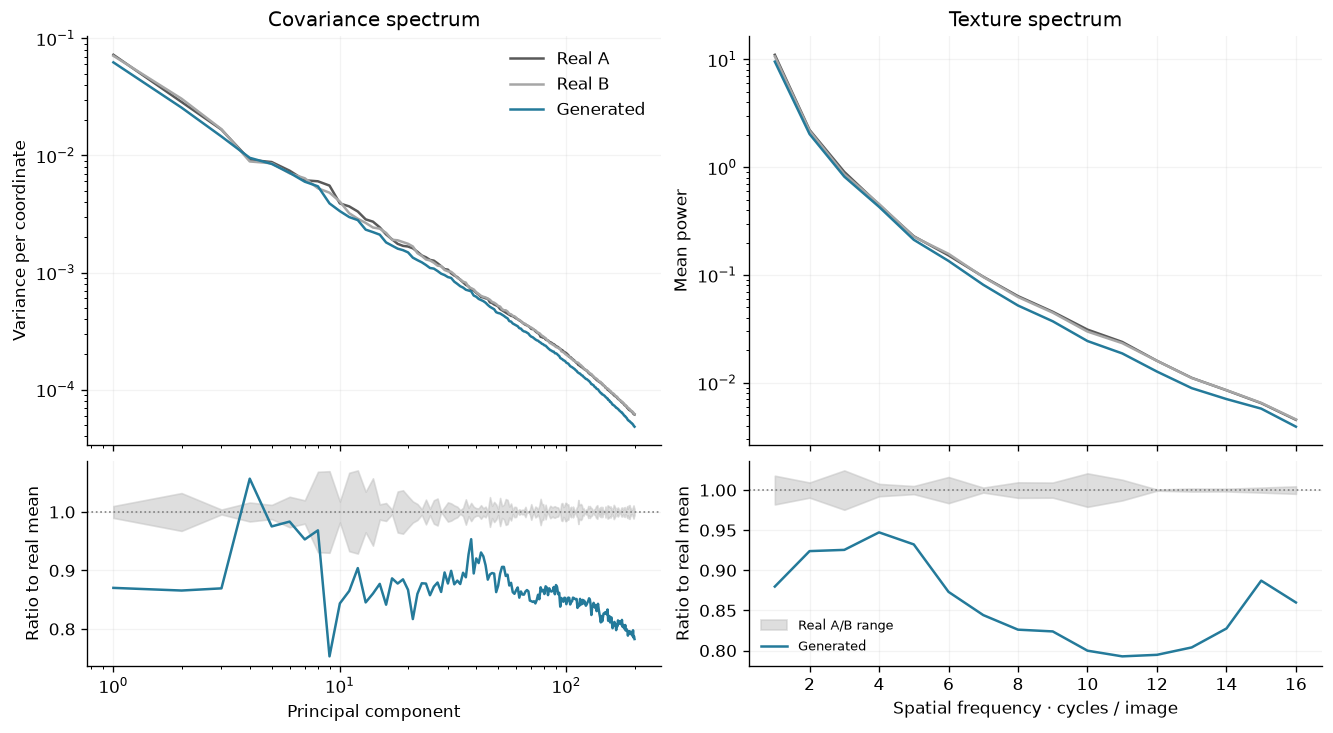

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex="col",
                         gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")
for i, (label, color) in enumerate(zip(["Real A", "Real B", "Generated"],
                                       ["0.35", "0.65", "#247a9a"])):
    axes[0, 0].loglog(np.arange(1, 201), spectra[i, :200], color=color, label=label)
    axes[0, 1].semilogy(frequency_bins, radial_power[i], color=color, label=label)
axes[0, 0].set(ylabel="Variance per coordinate",
             title="Covariance spectrum")
axes[0, 1].set(ylabel="Mean power", title="Texture spectrum")
for ax, xs, ratios, (low, high) in zip(
        axes[1], [np.arange(1, 201), frequency_bins],
        [spectrum_ratios, power_ratios], ratio_bounds):
    ax.fill_between(xs, low, high, color="0.75", alpha=0.5, label="Real A/B range")
    ax.axhline(1, color="0.5", ls=":", lw=1)
    ax.plot(xs, ratios[2], color="#247a9a", label="Generated")
    ax.set_ylabel("Ratio to real mean")
axes[1, 0].set_xlabel("Principal component")
axes[1, 1].set_xlabel("Spatial frequency · cycles / image")
for ax in axes.flat:
    ax.grid(alpha=0.15)
axes[0, 0].legend(frameon=False)
axes[1, 1].legend(frameon=False, fontsize=8)
plt.show()


### Class clouds

$$
x_{1/2}=\tfrac12(x_0+x_1),\qquad
h_\theta(x,t)=\operatorname{mean}_{u,v}H_\theta(x,t)_{u,v,:}.
$$

200 test images per class; t-SNE of bottleneck features after PCA to 50 dimensions.


In [38]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors


@jax.jit
def bottleneck_features(params, images, t):
    times = jnp.full((len(images), 1, 1, 1), t)
    return model_apply(params, images, times, return_features=True).mean(axis=(1, 2))


class_rng = np.random.default_rng(7)
test_labels = np.asarray(data["test"]["label"])
class_indices = np.concatenate([
    class_rng.choice(np.flatnonzero(test_labels == c), 200, replace=False)
    for c in range(10)
])
class_labels = test_labels[class_indices]
class_images = np.stack([
    np.asarray(img) for img in data["test"][class_indices.tolist()]["img"]
]).astype(np.float32) / 127.5 - 1
class_noise = class_rng.standard_normal(class_images.shape).astype(np.float32)
class_states = 0.5 * (class_noise + class_images)
features = np.concatenate([
    np.asarray(bottleneck_features(params, jnp.asarray(batch), 0.5))
    for batch in np.array_split(class_states, 32)
])

representations = [class_states.reshape(len(class_states), -1), features]
reduced_representations = [PCA(n_components=50, random_state=0).fit_transform(values)
                           for values in representations]
class_embedding = TSNE(n_components=2, perplexity=35, init="pca",
                       learning_rate="auto", random_state=0).fit_transform(reduced_representations[1])
class_neighbors, neighbor_accuracy = [], []
for reduced in reduced_representations:
    neighbors = NearestNeighbors(n_neighbors=16).fit(reduced).kneighbors(
        reduced, return_distance=False
    )[:, 1:]
    neighbor_labels = class_labels[neighbors]
    class_neighbors.append(np.stack([
        np.bincount(neighbor_labels[class_labels == c].ravel(), minlength=10)
        / (200 * 15) for c in range(10)
    ]))
    neighbor_accuracy.append(np.mean(neighbor_labels == class_labels[:, None]))
class_neighbors = np.asarray(class_neighbors)


cloud_embedding = class_embedding
cloud_bandwidth = np.sqrt(cloud_embedding.var(axis=0).mean()) * 200**(-1 / 6)
cloud_lo = cloud_embedding.min(axis=0) - 3 * cloud_bandwidth
cloud_hi = cloud_embedding.max(axis=0) + 3 * cloud_bandwidth
cloud_edges = [np.linspace(lo, hi, 161) for lo, hi in zip(cloud_lo, cloud_hi)]
cloud_centers = [(edges[:-1] + edges[1:]) / 2 for edges in cloud_edges]
cloud_spacing = np.array([edges[1] - edges[0] for edges in cloud_edges])
cloud_area = cloud_spacing.prod()


def enclosed_levels(density):
    ordered = np.sort(density.ravel())[::-1]
    mass = np.cumsum(ordered) * cloud_area
    return ordered[np.searchsorted(mass, [0.95, 0.80, 0.50])]


cloud_densities = []
for c in range(10):
    points = cloud_embedding[class_labels == c]
    counts, _, _ = np.histogram2d(points[:, 0], points[:, 1], bins=cloud_edges)
    density = gaussian_filter(counts, sigma=cloud_bandwidth / cloud_spacing,
                              mode="constant")
    cloud_densities.append(density / (density.sum() * cloud_area))
cloud_densities = np.asarray(cloud_densities)
cloud_levels = [enclosed_levels(density) for density in cloud_densities]
pooled_cloud = cloud_densities.mean(axis=0)
pooled_level = enclosed_levels(pooled_cloud)[0]


cloud_peaks = np.array([np.unravel_index(d.argmax(), d.shape) for d in cloud_densities])
cloud_modes = np.column_stack([cloud_centers[j][cloud_peaks[:, j]] for j in range(2)])


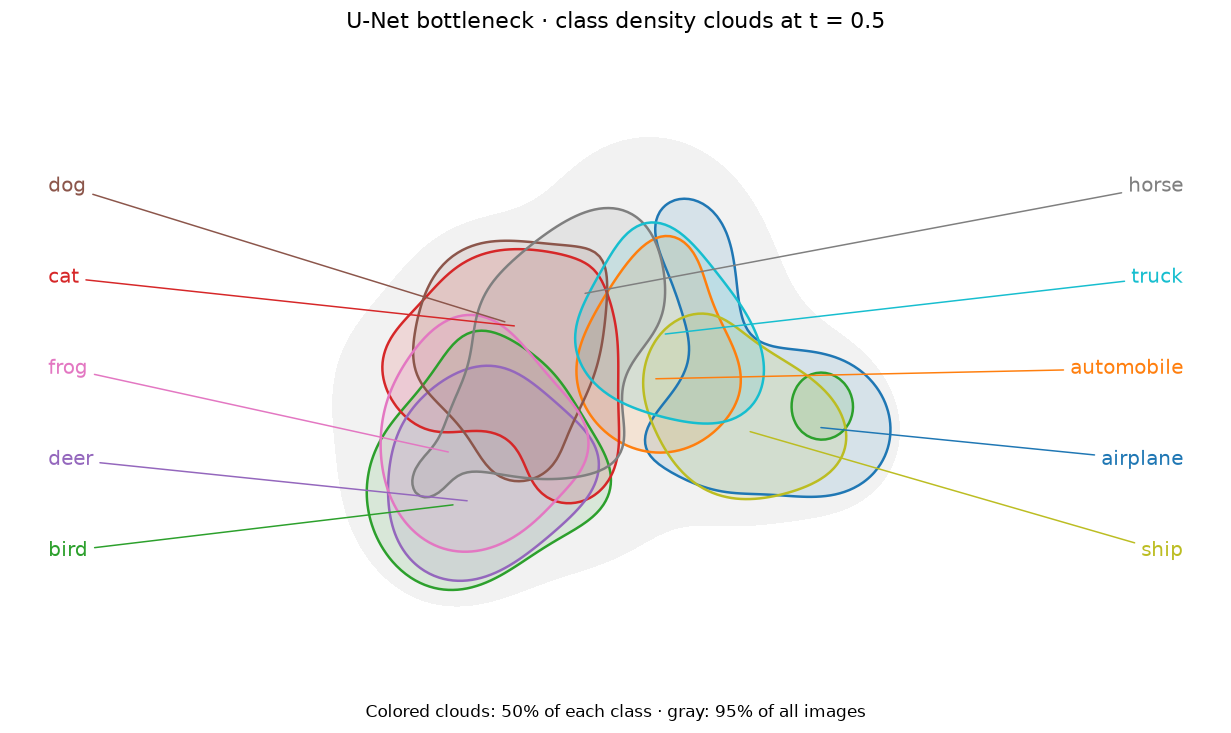

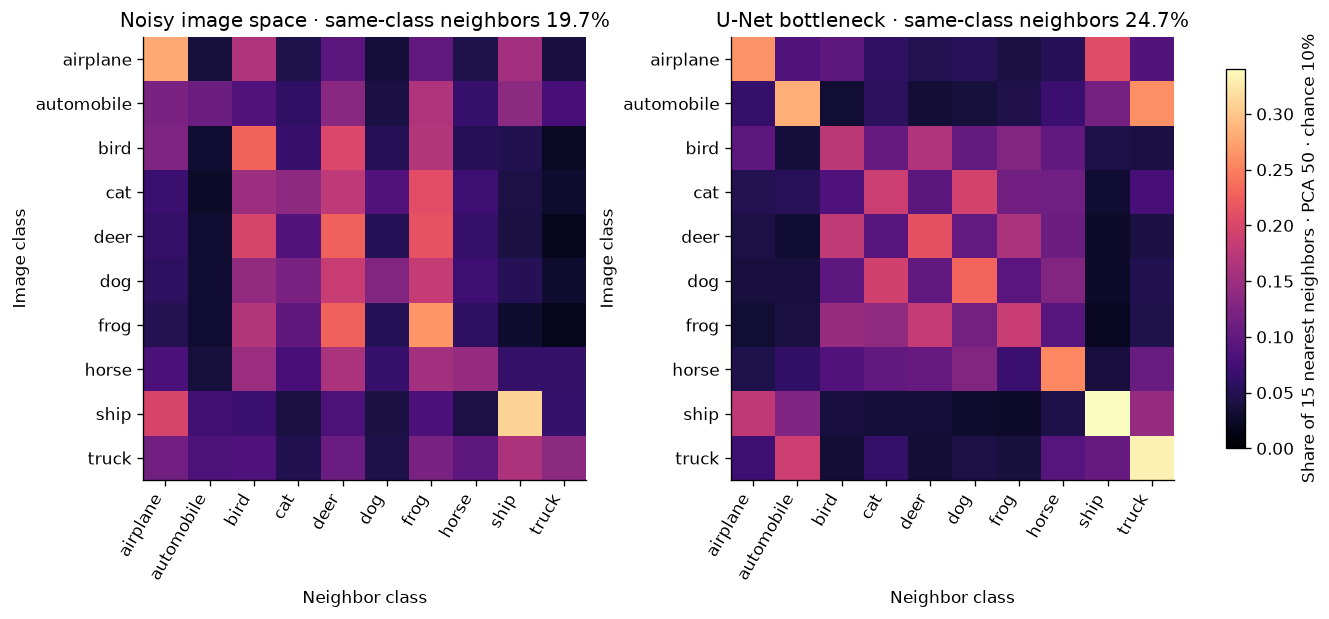

In [39]:
from matplotlib.colors import to_rgba

class_colors = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
ax.contourf(*cloud_centers, pooled_cloud.T,
            levels=[pooled_level, pooled_cloud.max() * 1.01], colors=["#f2f2f2"])
for c in range(10):
    ax.contourf(*cloud_centers, cloud_densities[c].T,
                levels=[cloud_levels[c][-1], cloud_densities[c].max() * 1.01],
                colors=[to_rgba(class_colors(c), 0.13)])
    ax.contour(*cloud_centers, cloud_densities[c].T,
               levels=[cloud_levels[c][-1]], colors=[class_colors(c)], linewidths=1.5)

# Label each cloud at its density peak.
order = np.argsort(cloud_modes[:, 0])
for side, classes in enumerate([order[:5], order[5:]]):
    classes = classes[np.argsort(cloud_modes[classes, 1])]
    for c, y in zip(classes, np.linspace(0.22, 0.78, 5)):
        ax.annotate(class_names[c], xy=cloud_modes[c],
                    xytext=(0.03 if side == 0 else 0.97, y), textcoords="axes fraction",
                    ha="left" if side == 0 else "right", va="center",
                    color=class_colors(c), fontsize=12,
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=2),
                    arrowprops=dict(arrowstyle="-", color=class_colors(c), lw=0.9,
                                    connectionstyle="arc3,rad=0", shrinkB=0))
margin = 0.30 * (cloud_hi[0] - cloud_lo[0])
ax.set(xlim=(cloud_lo[0] - margin, cloud_hi[0] + margin),
       ylim=(cloud_lo[1], cloud_hi[1]), aspect="equal")
ax.set_axis_off()
fig.suptitle("U-Net bottleneck · class density clouds at t = 0.5", fontsize=13)
fig.supxlabel("Colored clouds: 50% of each class · gray: 95% of all images", fontsize=10)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")

for ax, matrix, accuracy, name in zip(axes, class_neighbors, neighbor_accuracy,
                                      ["Noisy image space", "U-Net bottleneck"]):
    im = ax.imshow(matrix, cmap="magma", vmin=0, vmax=class_neighbors.max())
    ax.set(xticks=range(10), yticks=range(10), xticklabels=class_names,
           yticklabels=class_names, xlabel="Neighbor class", ylabel="Image class",
           title=f"{name} · same-class neighbors {accuracy:.1%}")
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
fig.colorbar(im, ax=axes, shrink=0.8,
             label="Share of 15 nearest neighbors · PCA 50 · chance 10%")
plt.show()
